# 03_etiquetado_zona_solo_nisar

In [1]:
# ---- 0. Packages ----
import gc, hashlib, json, os, re, shutil, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject
from scipy import ndimage
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEP = "=" * 40

In [2]:
# ---- 1. Configuration ----
from pathlib import Path
VARIANTE = "solo_nisar"

STACKS     = ["A_T148", "D_T011", "D_T112", "A_T047"]
FILTRO     = "lee_5"
FECHA_MIN  = "2026-06-01"
MARGEN_PREVIO = 5
MIN_REF    = 2
COB_MIN    = 0.05
GUARDAR_EXTRA = "durante"

# ---- Common grid of the subsets ----
EPSG, RES = 32618, 20
X0_MALLA, Y1_MALLA = 272_880, 796_440
NY_MALLA, NX_MALLA = 9144, 3351
BORDE_PX, PISO = 25, 1e-3

# ---- Clustering, consensus and rules ----
N_MUESTRA, K_GMM, LOTE = 200_000, range(4, 11), 2_000_000
P_SEGURO, P_DUDOSO, H_DUDOSO = 0.90, 0.70, 0.50
LR_AGUA, LR_VEG, FRAC_NUEVA, UMM_PX = -3.0, +2.5, 0.5, 9
URB_FRAC_BRILLO, URB_TEXTURA, URB_FRAC_OSCURO, URB_AREA_MIN = 0.15, 2.0, 0.10, 50
UMBRAL_AGUA_REF = -15.0
AGUA_REF_MIN_KM2 = 0.25
VEG_PERM_DB = 2.0
DIST_VEG_KM, DIST_URB_KM = 3.0, 2.0

# ---- Folders ----
DIR_BASE = next((c for c in (Path.cwd(), Path.cwd().parent) if (c / "metadatos").exists()), Path(".."))
DIR_META = DIR_BASE / "metadatos"
DIR_RECORTES = DIR_BASE / "recortes"
DIR_SUCESOS  = DIR_BASE / "sucesos"
DIR_ZONA     = DIR_BASE / "etiquetado_zona" / VARIANTE

CLASES = {0: ("Fuera de zona",            "#FFFFFF"), 1: ("Agua permanente",          "#08306B"),
          2: ("Agua abierta nueva",       "#41B6C4"), 3: ("Veg. inundada permanente", "#9E9AC8"),
          4: ("Veg. inundada nueva",      "#54278F"), 5: ("Bosque no inundado",       "#1B7837"),
          6: ("Veg. baja / pasto / suelo","#C2E699"), 7: ("Urbano",                   "#737373"),
          8: ("Urbano con aumento",       "#E6550D"), 9: ("Dudoso",                   "#FFD92F")}
CMAP_CLASES = ListedColormap([c for _, c in CLASES.values()])


def renglon(nombre, valor, fmt=""):
    print(f"{nombre:<28}: {valor:{fmt}}")


print(SEP)
renglon("Carpeta del proyecto", DIR_BASE)
renglon("Versión", VARIANTE)
renglon("Stacks", ", ".join(STACKS))
renglon("Filtro", FILTRO)
renglon("Salida", DIR_ZONA)
renglon("Espacio libre", f"{shutil.disk_usage(DIR_BASE).free / 1e9:.1f} GB")

Carpeta del proyecto        : C:\Users\Usuario\Desktop\NASA SAC
Versión                     : solo_nisar
Stacks                      : A_T148, D_T011, D_T112, A_T047
Filtro                      : lee_5
Salida                      : C:\Users\Usuario\Desktop\NASA SAC\etiquetado_zona\solo_nisar
Espacio libre               : 22.2 GB


In [3]:
# ---- 2. Common functions ----
def a_db(x):
    return 10 * np.log10(np.clip(x, PISO, None))


def media_local(img, valido, kernel):
    k = kernel.astype(np.float32)
    num = ndimage.correlate(np.where(valido, img, 0).astype(np.float32), k, mode="constant")
    den = ndimage.correlate(valido.astype(np.float32), k, mode="constant")
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan).astype(np.float32)


def desplazar(a, di, dj):
    b = np.full_like(a, np.nan)
    r0, r1 = max(0, -di), a.shape[0] - max(0, di)
    c0, c1 = max(0, -dj), a.shape[1] - max(0, dj)
    b[r0:r1, c0:c1] = a[r0 + di:r1 + di, c0 + dj:c1 + dj]
    return b


def otsu(x, bins=256):
    x = x[np.isfinite(x)]
    h, b = np.histogram(x, bins=bins)
    c = (b[:-1] + b[1:]) / 2
    w0 = np.cumsum(h); w1 = w0[-1] - w0
    m0 = np.cumsum(h * c) / np.maximum(w0, 1)
    m1 = (np.sum(h * c) - np.cumsum(h * c)) / np.maximum(w1, 1)
    return float(c[np.argmax(w0 * w1 * (m0 - m1) ** 2)])


def moda(x, paso=0.1, suavizado=5):
    x = x[np.isfinite(x)]
    h, b = np.histogram(x, bins=np.arange(np.floor(x.min()), np.ceil(x.max()) + paso, paso))
    h = np.convolve(h, np.ones(suavizado) / suavizado, mode="same")
    return float((b[np.argmax(h)] + b[np.argmax(h) + 1]) / 2)


def _lee(img, m, var, enl, refinado=False):
    cu2 = 1.0 / enl
    if refinado:
        w = np.maximum((var - m**2 * cu2) / (1 + cu2), 0) / np.maximum(var, 1e-20)
    else:
        w = np.clip(1 - cu2 * m**2 / np.maximum(var, 1e-20), 0, 1)
    return (m + w * (img - m)).astype(np.float32)


def f_boxcar(img, n=3):
    v = np.isfinite(img)
    return np.where(v, media_local(img, v, np.ones((n, n))), np.nan)


def f_lee(img, n=5):
    v = np.isfinite(img); k = np.ones((n, n))
    m = media_local(img, v, k); m2 = media_local(img**2, v, k)
    return np.where(v, _lee(img, m, np.maximum(m2 - m**2, 0), ENL), np.nan)


def _mascaras_rlee(n=7):
    h = n // 2
    i, j = np.mgrid[-h:h + 1, -h:h + 1]
    return {("h", +1): j >= 0,     ("h", -1): j <= 0,
            ("v", +1): i >= 0,     ("v", -1): i <= 0,
            ("d1", +1): i + j >= 0, ("d1", -1): i + j <= 0,
            ("d2", +1): j - i >= 0, ("d2", -1): j - i <= 0}


def f_refined_lee(img):
    v = np.isfinite(img)
    M = media_local(img, v, np.ones((3, 3)))
    pares = {"h": ((0, 2), (0, -2)), "v": ((2, 0), (-2, 0)),
             "d1": ((2, 2), (-2, -2)), "d2": ((-2, 2), (2, -2))}
    grad, lado = [], []
    for d, (a, b) in pares.items():
        ma, mb = desplazar(M, *a), desplazar(M, *b)
        grad.append(np.nan_to_num(np.abs(ma - mb), nan=-1))
        lado.append(np.where(np.abs(ma - M) <= np.abs(mb - M), 1, -1))
    dir_idx = np.argmax(np.stack(grad), axis=0)
    lado = np.take_along_axis(np.stack(lado), dir_idx[None], axis=0)[0]

    m_sel = np.full(img.shape, np.nan, np.float32); v_sel = np.full(img.shape, np.nan, np.float32)
    for n_d, d in enumerate(pares):
        for s in (+1, -1):
            sel = (dir_idx == n_d) & (lado == s)
            if not sel.any():
                continue
            k = MASCARAS_RLEE[(d, s)]
            m = media_local(img, v, k); m2 = media_local(img**2, v, k)
            m_sel[sel], v_sel[sel] = m[sel], np.maximum(m2 - m**2, 0)[sel]
    return np.where(v, _lee(img, m_sel, v_sel, ENL, refinado=True), np.nan)


def mapear(med, umbral_agua, ancla_hh, ancla_q):
    if med["HH"] < umbral_agua:
        return 2 if med["LR"] <= LR_AGUA else 1
    q_ok = (med["Q"] >= ancla_q + 1) if CON_HV else True
    if med["HH"] >= ancla_hh + 2 and q_ok:
        return 4 if med["LR"] >= LR_VEG else 3
    if med["HH"] <= ancla_hh - 3:
        return 6
    return 5


def tabla_clusters(etiquetas, hh, lr, q, umbral_agua, ancla_hh, ancla_q):
    q_ok = (q >= ancla_q + 1) if q is not None else np.ones_like(hh, bool)
    regla = {2: (hh < umbral_agua) & (lr <= LR_AGUA), 4: (hh >= ancla_hh + 2) & q_ok & (lr >= LR_VEG)}
    tabla = {}
    for c in np.unique(etiquetas):
        s = etiquetas == c
        med = {"HH": np.nanmedian(hh[s]), "LR": np.nanmedian(lr[s]),
               "Q": np.nanmedian(q[s]) if q is not None else None}
        k = mapear(med, umbral_agua, ancla_hh, ancla_q)
        if k in regla and regla[k][s].mean() < FRAC_NUEVA:
            k = 9
        tabla[int(c)] = k
    return tabla


def aplicar(tabla, etiquetas):
    lut = np.zeros(max(tabla) + 1, np.uint8)
    for c, k in tabla.items():
        lut[c] = k
    return lut[etiquetas]


def ajustar(Xs, semilla, k=None):
    ks = [k] if k else list(K_GMM)
    mejor = None
    for kk in ks:
        km = KMeans(kk, n_init=4, random_state=semilla).fit(Xs)
        g = GaussianMixture(kk, covariance_type="full", means_init=km.cluster_centers_,
                            reg_covar=1e-4, random_state=semilla).fit(Xs)
        bic = g.bic(Xs)
        if mejor is None or bic < mejor[2]:
            mejor = (km, g, bic)
    return mejor


def predecir(modelo, X, proba=False, lote=1_000_000):
    partes = [(modelo.predict_proba if proba else modelo.predict)(X[i:i + lote]) for i in range(0, len(X), lote)]
    return np.concatenate(partes)


def sha256(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


def https(href):
    if href.startswith("s3://"):
        cubeta, clave = href[5:].split("/", 1)
        return f"https://{cubeta}.s3.amazonaws.com/{clave}"
    return href


MASCARAS_RLEE = _mascaras_rlee(7)

In [4]:
# ---- 3. Dates of each stack and their role in the events ----
FASES = pd.read_csv(DIR_META / "fases_eventos.csv").fillna("")
FECHAS_EVENTO = sorted(pd.to_datetime(FASES["fecha_evento"].unique()))
NOMBRE_FASE = {"pre": "antes", "durante": "durante", "post": "despues"}


def papeles(stack):
    out = {}
    for r in FASES[FASES["stack"] == stack].itertuples():
        for fase in ("pre", "durante", "post"):
            for f in [x.strip() for x in str(getattr(r, fase)).split(",") if x.strip()]:
                out.setdefault(f, []).append(f"{NOMBRE_FASE[fase]} {r.evento}")
    return out


def fechas_stack(stack):
    filas = []
    for ruta in sorted((DIR_RECORTES / stack).glob("*/*.npz")):
        f = ruta.parent.name
        if f >= FECHA_MIN:
            filas.append({"fecha": f, "ruta": ruta, "frames": ruta.stem.count("F0")})
    inv = pd.DataFrame(filas)
    if inv.empty:
        return inv
    return inv.sort_values(["fecha", "frames"], ascending=[True, False]).drop_duplicates("fecha").reset_index(drop=True)


def es_libre(fecha, pap):
    if any(p.startswith("durante") for p in pap.get(fecha, [])):
        return False
    d = pd.Timestamp(fecha)
    return not any(0 < (fe - d).days <= MARGEN_PREVIO for fe in FECHAS_EVENTO)


print(SEP)
for st in STACKS:
    inv, pap = fechas_stack(st), papeles(st)
    if inv.empty:
        renglon(st, "sin recortes")
        continue
    txt = [f"{f}{'*' if es_libre(f, pap) else ''}{' (' + ', '.join(pap[f]) + ')' if f in pap else ''}" for f in inv["fecha"]]
    renglon(st, f"{len(inv)} fechas · " + " · ".join(txt))
print("* = fecha sin evento (entra al estado normal)")

A_T148                      : 5 fechas · 2026-06-24* (despues E4) · 2026-07-06* (antes E5) · 2026-08-11* (despues E5, antes E6) · 2026-09-04 (durante E6) · 2026-09-16* (despues E6)
D_T011                      : 6 fechas · 2026-06-26* (despues E4) · 2026-07-08* (antes E5) · 2026-07-20 (durante E5) · 2026-08-13* (despues E5, antes E6) · 2026-09-06 (durante E6) · 2026-09-18* (despues E6)
D_T112                      : 4 fechas · 2026-06-21* (despues E4, antes E5, antes E6) · 2026-08-20* (despues E5) · 2026-09-01 (durante E6) · 2026-09-25* (despues E6)
A_T047                      : 7 fechas · 2026-06-17* (despues E4) · 2026-07-11* (antes E5) · 2026-07-23 (durante E5) · 2026-08-16* (despues E5, antes E6) · 2026-08-28 (durante E6) · 2026-09-09 (durante E6) · 2026-09-21* (despues E6)
* = fecha sin evento (entra al estado normal)


## 4. Processing by stack

In [5]:
class Malla:
    def __init__(self, r0, r1, c0, c1):
        self.r0, self.r1, self.c0, self.c1 = r0, r1, c0, c1
        self.forma = (r1 - r0, c1 - c0)
        self.x0, self.y1 = X0_MALLA + c0 * RES, Y1_MALLA - r0 * RES
        self.transf = from_origin(self.x0, self.y1, RES, RES)
        self.caja = (self.x0, self.y1 - self.forma[0] * RES, self.x0 + self.forma[1] * RES, self.y1)

    def lonlat(self):
        from rasterio.warp import transform_bounds
        return transform_bounds(f"EPSG:{EPSG}", "EPSG:4326", *self.caja, densify_pts=21)


MALLA_ZONA = Malla(0, NY_MALLA, 0, NX_MALLA)


FILTROS = {"sin_filtro": lambda a: a, "boxcar_3": lambda a: f_boxcar(a, 3), "lee_5": lambda a: f_lee(a, 5),
           "refined_lee_7": lambda a: f_refined_lee(a)}


def cargar(stack):
    inv = fechas_stack(stack)
    caja = np.zeros((NY_MALLA, NX_MALLA), bool)
    for r in inv.itertuples():
        with np.load(r.ruta) as z:
            caja |= np.isfinite(z["HH"])
    filas, cols = np.where(caja.any(axis=1))[0], np.where(caja.any(axis=0))[0]
    malla = Malla(int(filas[0]), int(filas[-1]) + 1, int(cols[0]), int(cols[-1]) + 1)
    s = np.s_[malla.r0:malla.r1, malla.c0:malla.c1]
    huella = caja[s].copy()
    del caja
    datos = {}
    for r in inv.itertuples():
        with np.load(r.ruta) as z:
            hh = z["HH"][s].astype(np.float32)
            hv = z["HV"][s].astype(np.float32) if "HV" in z.files else None
        valido = np.isfinite(hh) & (np.isfinite(hv) if hv is not None else True)
        if valido.sum() < COB_MIN * huella.sum():
            renglon(f"  se omite {r.fecha}", f"cubre {valido.sum() / huella.sum():.0%} de la franja")
            continue
        etq, n_etq = ndimage.label(~valido)
        if n_etq:
            tam = ndimage.sum(np.ones_like(etq), etq, index=np.arange(1, n_etq + 1))
            grande = np.isin(etq, np.arange(1, n_etq + 1)[tam >= 500])
            valido &= ndimage.distance_transform_edt(~grande) > BORDE_PX
        hh = np.where(valido, np.clip(hh, PISO, None), np.nan).astype(np.float32)
        hv = np.where(valido, np.clip(hv, PISO, None), np.nan).astype(np.float32) if hv is not None else None
        datos[r.fecha] = {"HH": hh, "HV": hv, "valido": valido}
    return malla, huella, datos


def mediana_fechas(lista):
    pila = np.stack(lista)
    n = np.isfinite(pila).sum(axis=0)
    med = np.nanmedian(pila, axis=0)
    med[n < MIN_REF] = np.nan
    return med


def urbano_nisar(ref_db, valido):
    base = float(np.nanmedian(ref_db))
    r = np.nan_to_num(ref_db, nan=base)
    tex = np.sqrt(np.maximum(ndimage.uniform_filter(r**2, 7) - ndimage.uniform_filter(r, 7) ** 2, 0))
    brillo = ndimage.uniform_filter((r >= base + 5).astype(np.float32), 7)
    oscuro = ndimage.uniform_filter((r <= base - 8).astype(np.float32), 7)
    m = (brillo >= URB_FRAC_BRILLO) & (tex >= URB_TEXTURA * float(np.median(tex[valido]))) & (oscuro <= URB_FRAC_OSCURO)
    m = ndimage.binary_closing(m, np.ones((5, 5)))
    etq, n = ndimage.label(m)
    if n:
        tam = ndimage.sum(m, etq, index=np.arange(1, n + 1))
        m = np.isin(etq, np.arange(1, n + 1)[tam >= URB_AREA_MIN])
    return m & valido


def escribir_tif(ruta, datos, malla, dtype, nodata, etiquetas):
    ruta.parent.mkdir(parents=True, exist_ok=True)
    perfil = {"driver": "GTiff", "height": malla.forma[0], "width": malla.forma[1], "count": 1, "dtype": dtype,
              "crs": f"EPSG:{EPSG}", "transform": malla.transf, "nodata": nodata, "compress": "deflate", "tiled": True}
    with rasterio.open(ruta, "w", **perfil) as dst:
        dst.write(datos.astype(dtype), 1)
        dst.update_tags(**etiquetas)
    return ruta


def ficha(ruta, tipo, unidades, nodata, stack, fecha, libres, metodo, extra=None):
    f = {"esquema": "visor.ficha.v1", "tipo_producto": tipo, "fecha": fecha, "unidades": unidades,
         "fuente": "NISAR L2 GCOV, ASF DAAC",
         "advertencia": "Indicio exploratorio sin validar. Detección de cambio en una fecha observada; no es un pronóstico.",
         "procedencia": {"estado": "real_sin_validar", "sensor": f"NISAR L-SAR (banda L), stack {stack}",
                         "fechas": [f"referencia: mediana de {', '.join(libres)}", fecha],
                         "polarizaciones": ["HH", "HV"], "metodo": metodo,
                         "generado_por": {"modulo": "ml_choco", "notebook": f"etiquetado_zona_{VARIANTE}.ipynb"},
                         "generado_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                         "archivo": {"nombre": ruta.name, "sha256": sha256(ruta)}, "validacion": None},
         "fechas_detalle": {"observacion": fecha, "referencia": libres, "fecha_objetivo": None},
         "nodata": nodata, **(extra or {})}
    ruta.with_suffix(".json").write_text(json.dumps(f, ensure_ascii=False, indent=2), encoding="utf-8")


def solo_manchas_grandes(mascara, km2_min):
    lab, n = ndimage.label(mascara, np.ones((3, 3)))
    if n == 0:
        return mascara.copy()
    tam = ndimage.sum(mascara, lab, np.arange(1, n + 1)) * RES**2 / 1e6
    grandes = np.zeros(n + 1, bool)
    grandes[1:] = tam >= km2_min
    return grandes[lab]


def procesar_stack(stack):
    global ENL, CON_HV
    t0 = time.time()
    print(SEP)
    renglon("Stack", stack)
    malla, huella, datos = cargar(stack)
    fechas = sorted(datos)
    pap = papeles(stack)
    libres = [f for f in fechas if es_libre(f, pap)]
    assert len(libres) >= MIN_REF, f"{stack}: {len(libres)} fechas sin evento; hacen falta {MIN_REF}"
    renglon("Malla", f"{malla.forma[0]} x {malla.forma[1]} px · franja {huella.sum() * RES**2 / 1e6:,.0f} km²")
    renglon("Fechas", f"{len(fechas)} · referencia: {', '.join(libres)}")
    s_z = np.s_[malla.r0:malla.r1, malla.c0:malla.c1]

    # ---- Unfiltered references: water, urban and forest ----
    ref_crudo = a_db(np.nanmean(np.stack([datos[f]["HH"] for f in libres]), axis=0))
    med_crudo = mediana_fechas([a_db(datos[f]["HH"]) for f in libres])
    agua_nisar = ndimage.binary_opening(med_crudo < UMBRAL_AGUA_REF, np.ones((3, 3))) & huella
    agua_ref, urbano, zona_fija = agua_nisar, urbano_nisar(ref_crudo, huella), huella.copy()
    origen_urb = "NISAR (brillo persistente + textura, a ≤ 2 km de agua)"
    agua_prox = solo_manchas_grandes(agua_nisar, AGUA_REF_MIN_KM2)
    d_agua_km = (ndimage.distance_transform_edt(~agua_prox) * RES / 1000 if agua_prox.any()
                 else np.full(malla.forma, np.inf, np.float32))
    del agua_prox
    planicie = d_agua_km <= DIST_VEG_KM
    urbano &= d_agua_km <= DIST_URB_KM
    del d_agua_km
    cerca_agua = agua_ref | (ndimage.distance_transform_edt(~agua_ref) <= 15)
    renglon("Urbano", f"{origen_urb}: {urbano.sum() * RES**2 / 1e6:.1f} km²")
    renglon("Zona de análisis", f"{zona_fija.sum() / max(huella.sum(), 1):.0%} de la franja")

    f0 = libres[0]
    hh0 = datos[f0]["HH"]
    base = moda(a_db(hh0)[datos[f0]["valido"] & ~agua_nisar][::7])
    bosque = datos[f0]["valido"] & (np.abs(med_crudo - base) <= 1.0) & ~agua_nisar
    k7 = np.ones((7, 7))
    m = media_local(hh0, bosque, k7); m2 = media_local(hh0**2, bosque, k7)
    ENL = float(np.clip(np.nanmedian((m**2 / np.maximum(m2 - m**2, 1e-12))[bosque]), 1, 50))
    del m, m2, ref_crudo, med_crudo
    renglon("ENL estimado", f"{ENL:.1f}")

    # ---- Filter and conversion to dB ----
    for f in fechas:
        for p in ("HH", "HV"):
            if datos[f][p] is not None:
                datos[f][p] = a_db(FILTROS[FILTRO](datos[f][p])).astype(np.float32)
                datos[f][p][~datos[f]["valido"]] = np.nan
    gc.collect()

    # ---- Normal state of the stack ----
    hh_ref = mediana_fechas([datos[f]["HH"] for f in libres])
    libres_hv = [f for f in libres if datos[f]["HV"] is not None]
    hv_ref = mediana_fechas([datos[f]["HV"] for f in libres_hv]) if len(libres_hv) >= MIN_REF else None
    pila = np.stack([datos[f]["HH"] for f in fechas])
    n_f = np.isfinite(pila).sum(axis=0)
    hh_max = np.where(n_f >= 2, np.nanmax(pila, axis=0), np.nan)
    hh_min = np.where(n_f >= 2, np.nanmin(pila, axis=0), np.nan)
    med_todas = np.nanmedian(pila[:, ::4, ::4], axis=0)
    del pila
    ancla_stack = moda(med_todas[np.isfinite(med_todas) & ~agua_nisar[::4, ::4]])
    brillante_siempre = (hh_min >= ancla_stack + VEG_PERM_DB) & planicie & ~agua_nisar
    del hh_min, med_todas
    renglon("Brillante en todas las fechas", f"{brillante_siempre.sum() * RES**2 / 1e6:.1f} km² (HH_min ≥ {ancla_stack + VEG_PERM_DB:.1f} dB)")
    gc.collect()

    # ---- One model per date type (with HV / HH only) ----
    def feats(f, mascara, con_hv):
        cols = [datos[f]["HH"][mascara], datos[f]["HV"][mascara] if con_hv else None, (datos[f]["HH"] - hh_ref)[mascara]]
        return np.column_stack([c for c in cols if c is not None]).astype(np.float32)

    def zona_de(f, con_hv):
        z = zona_fija & datos[f]["valido"] & np.isfinite(hh_ref) & np.isfinite(datos[f]["HH"])
        return z & np.isfinite(datos[f]["HV"]) if con_hv else z

    rng = np.random.default_rng(0)
    modelos = {}
    for con_hv in (True, False):
        grupo = [f for f in fechas if (datos[f]["HV"] is not None and hv_ref is not None) == con_hv]
        if not grupo:
            continue
        muestras = []
        for f in grupo:
            idx = np.flatnonzero(zona_de(f, con_hv))
            if idx.size:
                sel = rng.choice(idx, min(N_MUESTRA // len(grupo) + 1, idx.size), replace=False)
                mm = np.zeros(malla.forma, bool).ravel(); mm[sel] = True
                muestras.append(feats(f, mm.reshape(malla.forma), con_hv))
        X = np.concatenate(muestras)
        lo, hi = np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0)
        Xc = np.clip(X, lo, hi)
        mu, sd = Xc.mean(axis=0), Xc.std(axis=0)
        km, gmm, _ = ajustar((Xc - mu) / sd, 0)
        modelos[con_hv] = {"km": km, "gmm": gmm, "lo": lo, "hi": hi, "mu": mu, "sd": sd, "fechas": grupo}
        renglon(f"Modelo {'HH+HV' if con_hv else 'solo HH'}", f"k = {gmm.n_components} · {len(X):,} píxeles de {len(grupo)} fechas")

    # ---- Labeling of each date ----
    salida = DIR_ZONA / stack
    filas, rutas = [], {}
    durantes = {f for f, ps in pap.items() if any(p.startswith("durante") for p in ps)}
    for f in fechas:
        con_hv = datos[f]["HV"] is not None and hv_ref is not None
        CON_HV = con_hv
        md = modelos[con_hv]
        zona = zona_de(f, con_hv)
        hh, lr = datos[f]["HH"], datos[f]["HH"] - hh_ref
        q = (datos[f]["HH"] - datos[f]["HV"]) if con_hv else None
        X = (np.clip(feats(f, zona, con_hv), md["lo"], md["hi"]) - md["mu"]) / md["sd"]
        lab_km, lab_g = predecir(md["km"], X), predecir(md["gmm"], X)

        hh_z, lr_z = hh[zona], lr[zona]
        q_z = q[zona] if con_hv else None
        cerca = cerca_agua[zona]
        umbral = otsu(hh_z[cerca][::3]) if cerca.sum() > 5000 else -18.0
        umbral = float(np.clip(umbral, -21, -15))
        sub = rng.choice(hh_z.size, min(2_000_000, hh_z.size), replace=False)
        ancla = moda(hh_z[sub][hh_z[sub] >= umbral])
        ancla_q = moda(q_z[sub][hh_z[sub] >= umbral]) if con_hv else None
        reglas = (umbral, ancla, ancla_q)
        args_sub = (hh_z[sub], lr_z[sub], q_z[sub] if con_hv else None)
        t_km = tabla_clusters(lab_km[sub], *args_sub, *reglas)
        t_g = tabla_clusters(lab_g[sub], *args_sub, *reglas)
        for t_, lab in ((t_km, lab_km), (t_g, lab_g)):
            for c in np.unique(lab):
                t_.setdefault(int(c), 9)
        c_km = aplicar(t_km, lab_km)
        k = md["gmm"].n_components
        clases_g = sorted(set(t_g.values()))
        c_g = np.empty(X.shape[0], np.uint8); pmax = np.empty(X.shape[0], np.float32); H = np.empty(X.shape[0], np.float32)
        for i in range(0, X.shape[0], LOTE):
            P = md["gmm"].predict_proba(X[i:i + LOTE])
            Pc = np.column_stack([P[:, [c for c in range(k) if t_g.get(c) == cl]].sum(axis=1) for cl in clases_g])
            c_g[i:i + LOTE] = np.array(clases_g, np.uint8)[np.argmax(Pc, axis=1)]
            pmax[i:i + LOTE] = Pc.max(axis=1)
            H[i:i + LOTE] = (-(Pc * np.log(np.clip(Pc, 1e-12, None))).sum(axis=1) / np.log(len(clases_g))
                             if len(clases_g) > 1 else 0)
        del X, lab_km, lab_g
        dudoso = (c_km != c_g) | (pmax < P_DUDOSO) | (H > H_DUDOSO)
        clase = np.full(malla.forma, 255, np.uint8)
        clase[datos[f]["valido"]] = 0
        clase[zona] = np.where(dudoso, 9, c_g)
        pm = np.full(malla.forma, np.nan, np.float32); pm[zona] = pmax
        seguro_pct = float(((c_km == c_g) & (pmax >= P_SEGURO) & ~dudoso).mean() * 100)
        del c_km, c_g, pmax, H, dudoso

        q_ok = (q >= ancla_q + 1) if con_hv else True
        for cl, mreg in {2: zona & (hh < umbral) & (lr <= LR_AGUA), 4: zona & (hh >= ancla + 2) & q_ok & (lr >= LR_VEG)}.items():
            etq, n_ = ndimage.label(mreg, structure=np.ones((3, 3)))
            if n_:
                tam = ndimage.sum(mreg, etq, index=np.arange(1, n_ + 1))
                clase[np.isin(etq, np.arange(1, n_ + 1)[tam >= UMM_PX]) & (clase != cl)] = cl
            del etq
        clase[zona & (clase == 3) & ~brillante_siempre] = 5
        clase[zona & brillante_siempre & np.isin(clase, [3, 4, 5, 6, 9])] = 3
        clase[zona & (clase == 4) & ~planicie] = 9
        clase[zona & (clase == 2) & (hh_max < umbral)] = 1
        urb = zona & urbano
        clase[urb] = np.where(lr[urb] >= 3, 8, 7)

        f8 = f.replace("-", "")
        etiquetas = {"TIPO_PRODUCTO": "clases_inundacion_nisar", "UNIDADES": "clase", "FECHA": f, "SENSOR": "NISAR L-SAR",
                     "POLARIZACION": "HH,HV" if con_hv else "HH", "VERSION_MODELO": f"zona_{VARIANTE}_{FILTRO}"}
        metodo = (f"Toda la franja del stack {stack}; filtro {FILTRO} (ENL {ENL:.1f}); un K-means→GMM por stack "
                  f"(k={k}); mapeo relativo por fecha (Otsu {umbral:.1f} dB, bosque {ancla:.1f} dB); consenso; "
                  f"refinamiento por píxel; agua permanente por HH_max; veg. inundada permanente por HH_min ≥ bosque + {VEG_PERM_DB} dB"
                  + f" y a ≤ {DIST_VEG_KM} km de agua; urbano: {origen_urb}")
        ruta_c = escribir_tif(salida / "clases" / f"{stack}_{f8}_clases_{VARIANTE}.tif", clase, malla, "uint8", 255, etiquetas)
        ficha(ruta_c, "clases_inundacion_nisar", "clase", 255, stack, f, libres, metodo,
              {"clases": {str(c): {"nombre": v[0], "color": v[1]} for c, v in CLASES.items()} | {"255": {"nombre": "Sin dato"}}})
        rutas[f] = {"clases": ruta_c}
        if GUARDAR_EXTRA == "todas" or (GUARDAR_EXTRA == "durante" and f in durantes):
            r_lr = escribir_tif(salida / "durante" / f"{stack}_{f8}_LR_ref_HH_{VARIANTE}.tif",
                                np.where(zona, lr, -9999), malla, "float32", -9999, {**etiquetas, "TIPO_PRODUCTO": "diferencia_db", "UNIDADES": "dB"})
            ficha(r_lr, "diferencia_db", "dB", -9999, stack, f, libres, metodo)
            r_pm = escribir_tif(salida / "durante" / f"{stack}_{f8}_pmax_{VARIANTE}.tif",
                                np.where(np.isfinite(pm), np.round(pm * 100), 255), malla, "uint8", 255,
                                {**etiquetas, "TIPO_PRODUCTO": "pmax_gmm", "UNIDADES": "%"})
            ficha(r_pm, "pmax_gmm", "%", 255, stack, f, libres, metodo)
            rutas[f].update({"LR": r_lr, "pmax": r_pm})
        km2 = lambda cs: float(np.isin(clase, cs).sum() * RES**2 / 1e6)
        filas.append({"stack": stack, "fecha": f, "papel": ", ".join(pap.get(f, [])) or ("referencia" if f in libres else ""),
                      "pols": "HH+HV" if con_hv else "HH", "cubre_km2": float(datos[f]["valido"].sum() * RES**2 / 1e6),
                      "umbral_agua_dB": umbral, "ancla_bosque_dB": ancla, "pct_seguro": seguro_pct,
                      **{f"{c}_{CLASES[c][0]}_km2": km2([c]) for c in range(1, 10)},
                      "inundacion_nueva_km2": km2([2, 4])})
        renglon(f"  {f}", f"{filas[-1]['papel'] or '-':<22} agua nueva {km2([2]):6.2f} · veg. inund. nueva "
                f"{km2([4]):6.2f} · dudoso {km2([9]):7.1f} km²")
        fig, ax = plt.subplots(figsize=(4.5, 4.5 * malla.forma[0] / malla.forma[1] + 0.8), layout="constrained")
        vista = clase[::3, ::3].astype(float); vista[vista == 255] = np.nan
        ext = [malla.caja[0] / 1e3, malla.caja[2] / 1e3, malla.caja[1] / 1e3, malla.caja[3] / 1e3]
        ax.imshow(vista, cmap=CMAP_CLASES, vmin=-0.5, vmax=9.5, extent=ext, interpolation="nearest")
        ax.set_title(f"{stack} · {f}\n{filas[-1]['papel']}", fontsize=9); ax.set_xlabel("Este (km)"); ax.set_ylabel("Norte (km)")
        (salida / "figuras").mkdir(parents=True, exist_ok=True)
        rutas[f]["png"] = salida / "figuras" / f"{stack}_{f8}_clases_{VARIANTE}.png"
        fig.savefig(rutas[f]["png"], dpi=110)
        plt.close(fig)
        del clase, pm, hh, lr, q, zona
        gc.collect()

    serie = pd.DataFrame(filas)
    serie.round(3).to_csv(salida / f"serie_{stack}_{VARIANTE}.csv", index=False)
    (salida / f"modelo_{stack}_{VARIANTE}.json").write_text(json.dumps(
        {"stack": stack, "filtro": FILTRO, "ENL": ENL, "referencia": libres, "fechas": fechas,
         "malla": {"x0": malla.x0, "y1": malla.y1, "res": RES, "forma": list(malla.forma), "epsg": EPSG},
         "modelos": {("HH+HV" if k_ else "HH"): {"k": int(v["gmm"].n_components), "fechas": v["fechas"]} for k_, v in modelos.items()},
         "urbano": origen_urb}, ensure_ascii=False, indent=2), encoding="utf-8")
    graficar_serie(stack, serie, rutas, malla)
    renglon("Tiempo", f"{time.time() - t0:.0f} s")
    del datos
    gc.collect()
    return serie, rutas, malla


def graficar_serie(stack, serie, rutas, malla):
    salida = DIR_ZONA / stack / "figuras"
    n = len(serie)
    fig, ejes = plt.subplots(1, n, figsize=(2.6 * n + 1, 2.6 * malla.forma[0] / malla.forma[1] + 1.2), squeeze=False,
                             layout="constrained")
    ext = [malla.caja[0] / 1e3, malla.caja[2] / 1e3, malla.caja[1] / 1e3, malla.caja[3] / 1e3]
    for ax, r in zip(ejes[0], serie.itertuples()):
        with rasterio.open(rutas[r.fecha]["clases"]) as src:
            c = src.read(1, out_shape=(src.height // 3, src.width // 3), resampling=Resampling.nearest).astype(float)
        c[c == 255] = np.nan
        ax.imshow(c, cmap=CMAP_CLASES, vmin=-0.5, vmax=9.5, extent=ext, interpolation="nearest")
        ax.set_title(f"{r.fecha}\n{r.papel}", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c_) for _, c_ in list(CLASES.values())[1:]],
               labels=[n_ for n_, _ in list(CLASES.values())[1:]], loc="outside lower center", ncol=5, fontsize=7)
    fig.suptitle(f"{stack} · todas las fechas · {VARIANTE} · REAL SIN VALIDAR", fontsize=10)
    fig.savefig(salida / f"{stack}_todas_las_fechas_{VARIANTE}.png", dpi=110)
    plt.show()
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
    fx = pd.to_datetime(serie["fecha"])
    for c, a_ in ((2, 0), (4, 0), (8, 0), (1, 1), (3, 1), (9, 1)):
        ax[a_].plot(fx, serie[f"{c}_{CLASES[c][0]}_km2"], "o-", color=CLASES[c][1], label=CLASES[c][0])
    for a_ in ax:
        for fe in FECHAS_EVENTO:
            if fx.min() - pd.Timedelta(days=15) <= fe <= fx.max() + pd.Timedelta(days=15):
                a_.axvline(fe, color="k", lw=0.8, ls="--")
        a_.set_ylabel("km²"); a_.legend(fontsize=8); a_.tick_params(axis="x", rotation=30)
    ax[0].set_title("Cambios (nuevo frente al estado normal)", fontsize=10)
    ax[1].set_title("Agua y vegetación inundada permanentes, y dudoso", fontsize=10)
    fig.suptitle(f"{stack} · serie de tiempo · líneas punteadas = eventos E1–E6", fontsize=10)
    fig.savefig(salida / f"{stack}_serie_tiempo_{VARIANTE}.png", dpi=110)
    plt.show()

Stack                       : A_T148
Malla                       : 9144 x 3351 px · franja 10,896 km²
Fechas                      : 5 · referencia: 2026-06-24, 2026-07-06, 2026-08-11, 2026-09-16
Urbano                      : NISAR (brillo persistente + textura, a ≤ 2 km de agua): 4.1 km²
Zona de análisis            : 100% de la franja
ENL estimado                : 9.9
Brillante en todas las fechas: 112.1 km² (HH_min ≥ -2.9 dB)
Modelo HH+HV                : k = 6 · 200,005 píxeles de 5 fechas
  2026-06-24                : despues E4             agua nueva   2.21 · veg. inund. nueva   2.60 · dudoso  1946.3 km²
  2026-07-06                : antes E5               agua nueva   0.00 · veg. inund. nueva   0.01 · dudoso   664.7 km²
  2026-08-11                : despues E5, antes E6   agua nueva   0.30 · veg. inund. nueva   0.48 · dudoso   393.8 km²
  2026-09-04                : durante E6             agua nueva   4.16 · veg. inund. nueva   6.63 · dudoso   589.2 km²
  2026-09-16               

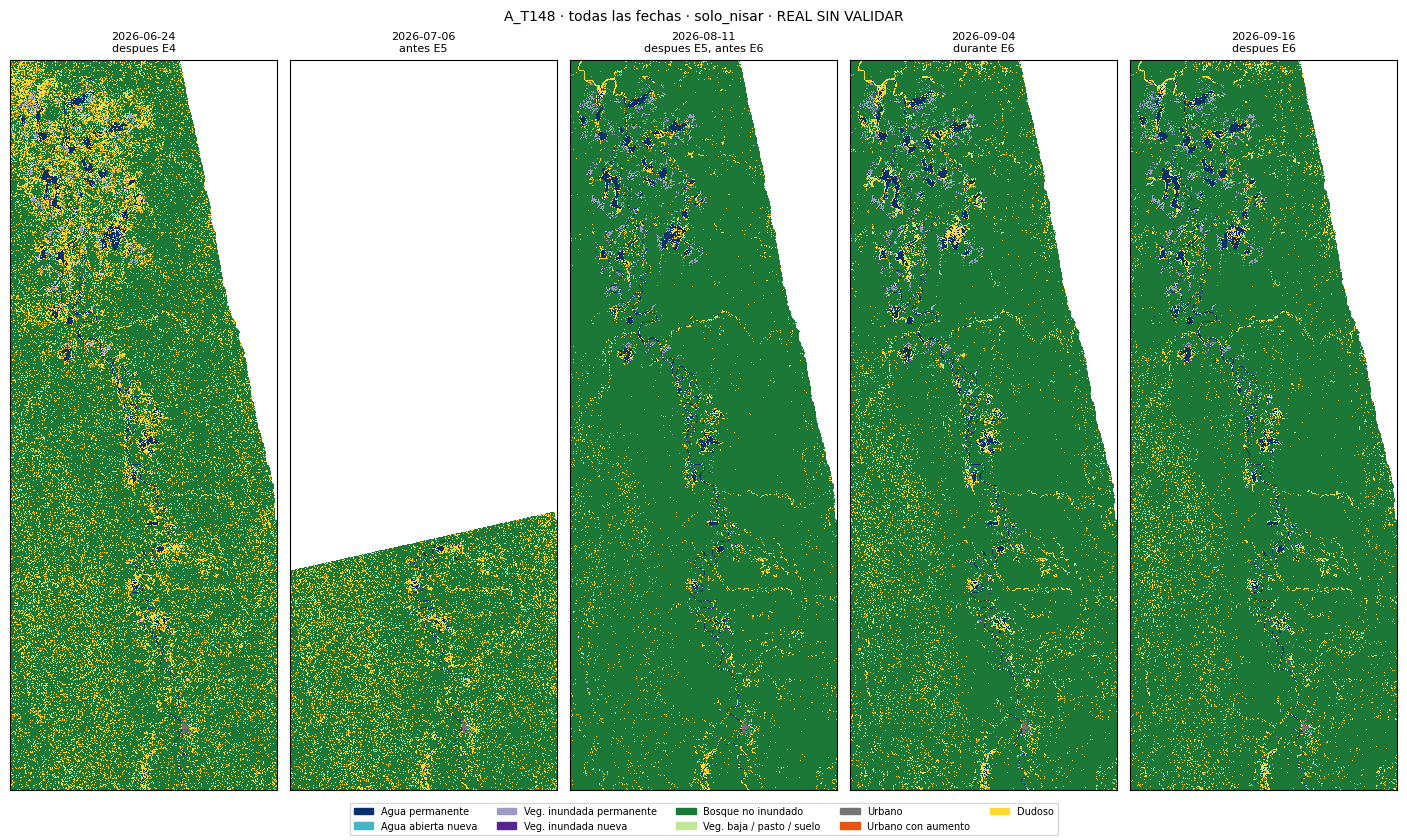

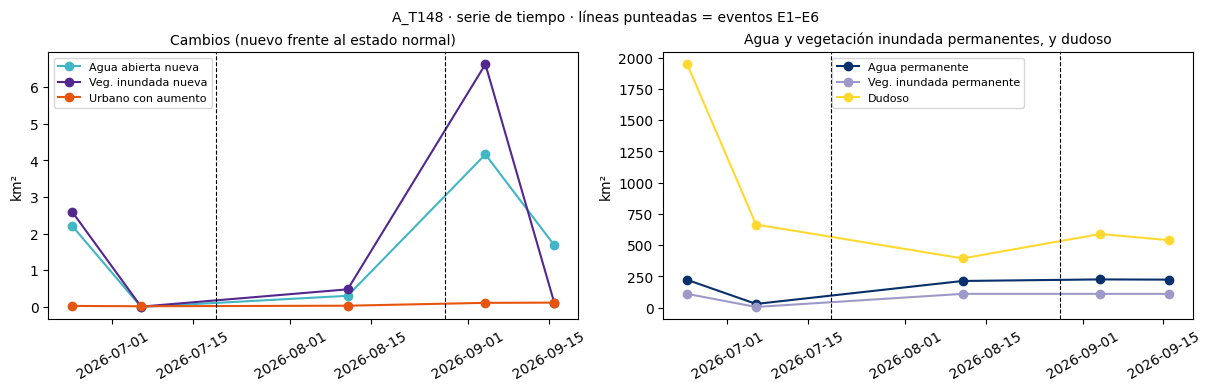

Tiempo                      : 717 s
Stack                       : D_T011
Malla                       : 9144 x 3351 px · franja 9,373 km²
Fechas                      : 6 · referencia: 2026-06-26, 2026-07-08, 2026-08-13, 2026-09-18
Urbano                      : NISAR (brillo persistente + textura, a ≤ 2 km de agua): 4.0 km²
Zona de análisis            : 100% de la franja
ENL estimado                : 14.3
Brillante en todas las fechas: 17.1 km² (HH_min ≥ -3.8 dB)
Modelo HH+HV                : k = 10 · 200,004 píxeles de 6 fechas
  2026-06-26                : despues E4             agua nueva   1.12 · veg. inund. nueva   0.18 · dudoso  1463.4 km²
  2026-07-08                : antes E5               agua nueva   0.03 · veg. inund. nueva   0.12 · dudoso  1512.5 km²
  2026-07-20                : durante E5             agua nueva   1.08 · veg. inund. nueva   0.11 · dudoso   934.6 km²
  2026-08-13                : despues E5, antes E6   agua nueva   0.18 · veg. inund. nueva   0.00 · dudoso   7

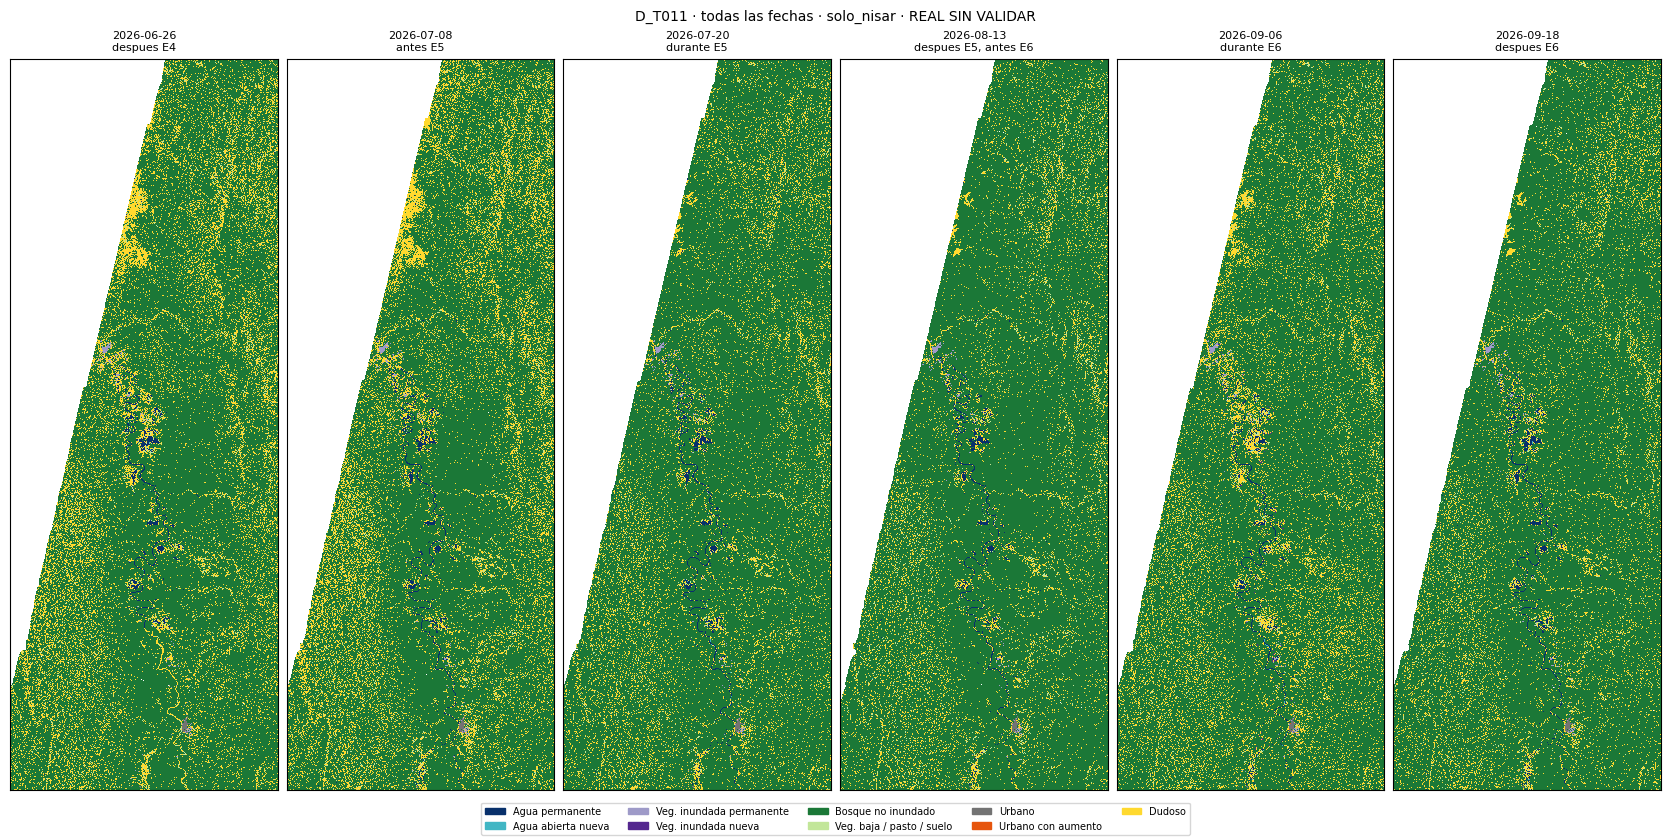

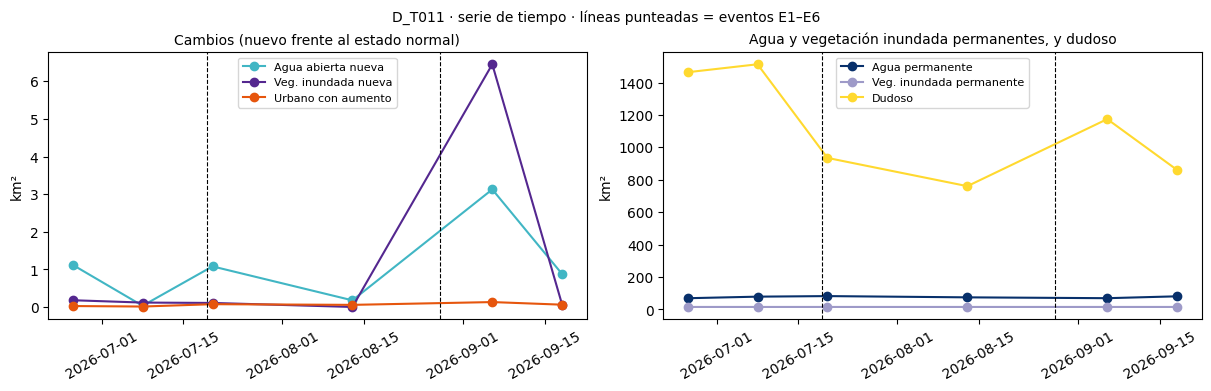

Tiempo                      : 998 s
Stack                       : D_T112
Malla                       : 8946 x 2928 px · franja 6,675 km²
Fechas                      : 4 · referencia: 2026-06-21, 2026-08-20, 2026-09-25
Urbano                      : NISAR (brillo persistente + textura, a ≤ 2 km de agua): 0.4 km²
Zona de análisis            : 100% de la franja
ENL estimado                : 12.3
Brillante en todas las fechas: 72.2 km² (HH_min ≥ -3.2 dB)
Modelo HH+HV                : k = 10 · 200,001 píxeles de 3 fechas
Modelo solo HH              : k = 10 · 200,001 píxeles de 1 fechas
  2026-06-21                : despues E4, antes E5, antes E6 agua nueva   0.27 · veg. inund. nueva   3.82 · dudoso  1075.2 km²
  2026-08-20                : despues E5             agua nueva   4.17 · veg. inund. nueva   0.62 · dudoso   190.6 km²
  2026-09-01                : durante E6             agua nueva   0.38 · veg. inund. nueva   3.83 · dudoso   895.1 km²
  2026-09-25                : despues E6       

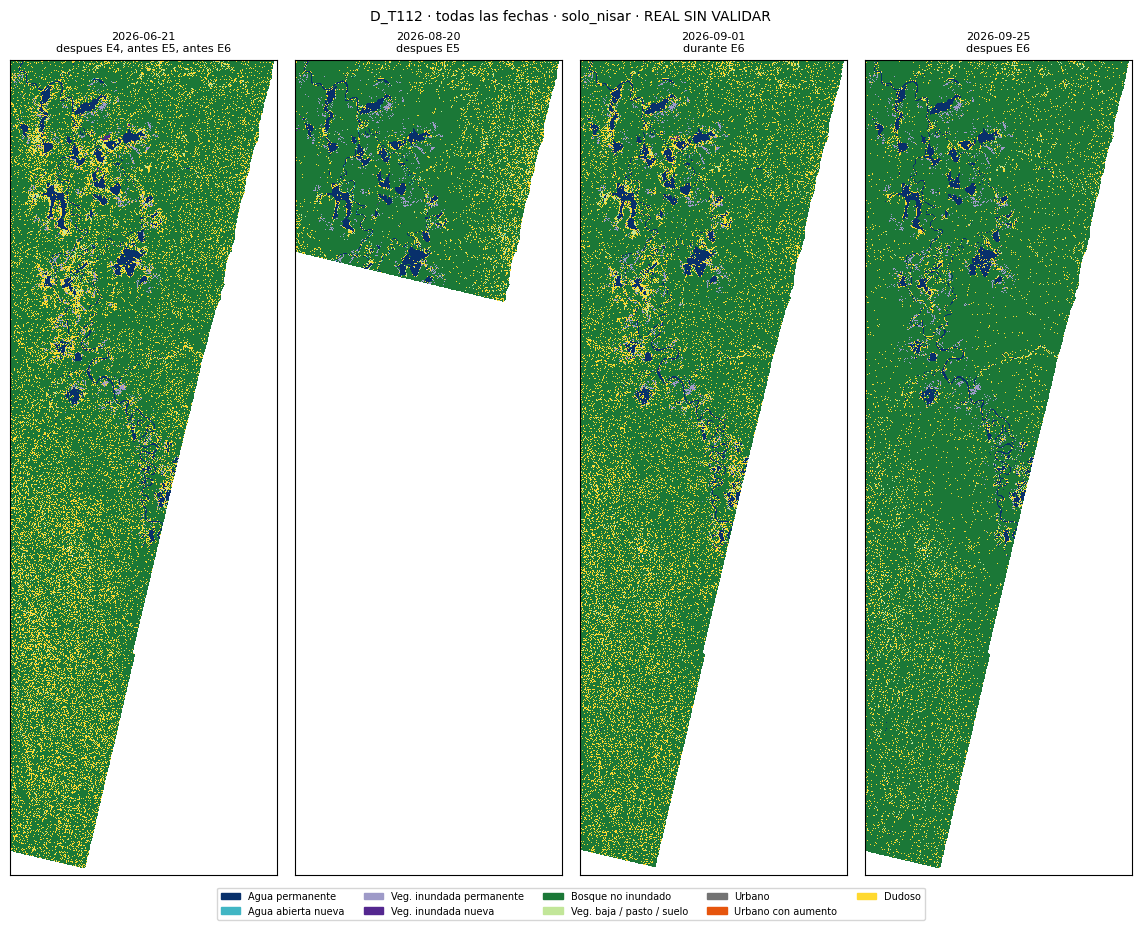

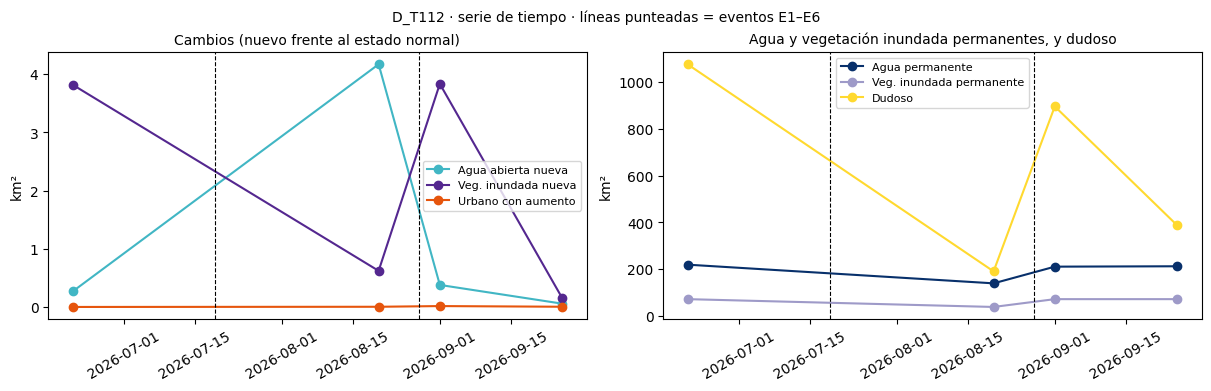

Tiempo                      : 516 s
Stack                       : A_T047
Malla                       : 9096 x 2136 px · franja 3,871 km²
Fechas                      : 7 · referencia: 2026-06-17, 2026-07-11, 2026-08-16, 2026-09-21
Urbano                      : NISAR (brillo persistente + textura, a ≤ 2 km de agua): 0.0 km²
Zona de análisis            : 100% de la franja
ENL estimado                : 14.2
Brillante en todas las fechas: 0.0 km² (HH_min ≥ -2.9 dB)
Modelo HH+HV                : k = 10 · 200,004 píxeles de 7 fechas
  2026-06-17                : despues E4             agua nueva   0.02 · veg. inund. nueva   0.00 · dudoso   268.2 km²
  2026-07-11                : antes E5               agua nueva   0.00 · veg. inund. nueva   0.00 · dudoso   198.7 km²
  2026-07-23                : durante E5             agua nueva   0.00 · veg. inund. nueva   0.00 · dudoso   318.0 km²
  2026-08-16                : despues E5, antes E6   agua nueva   0.00 · veg. inund. nueva   0.00 · dudoso   49

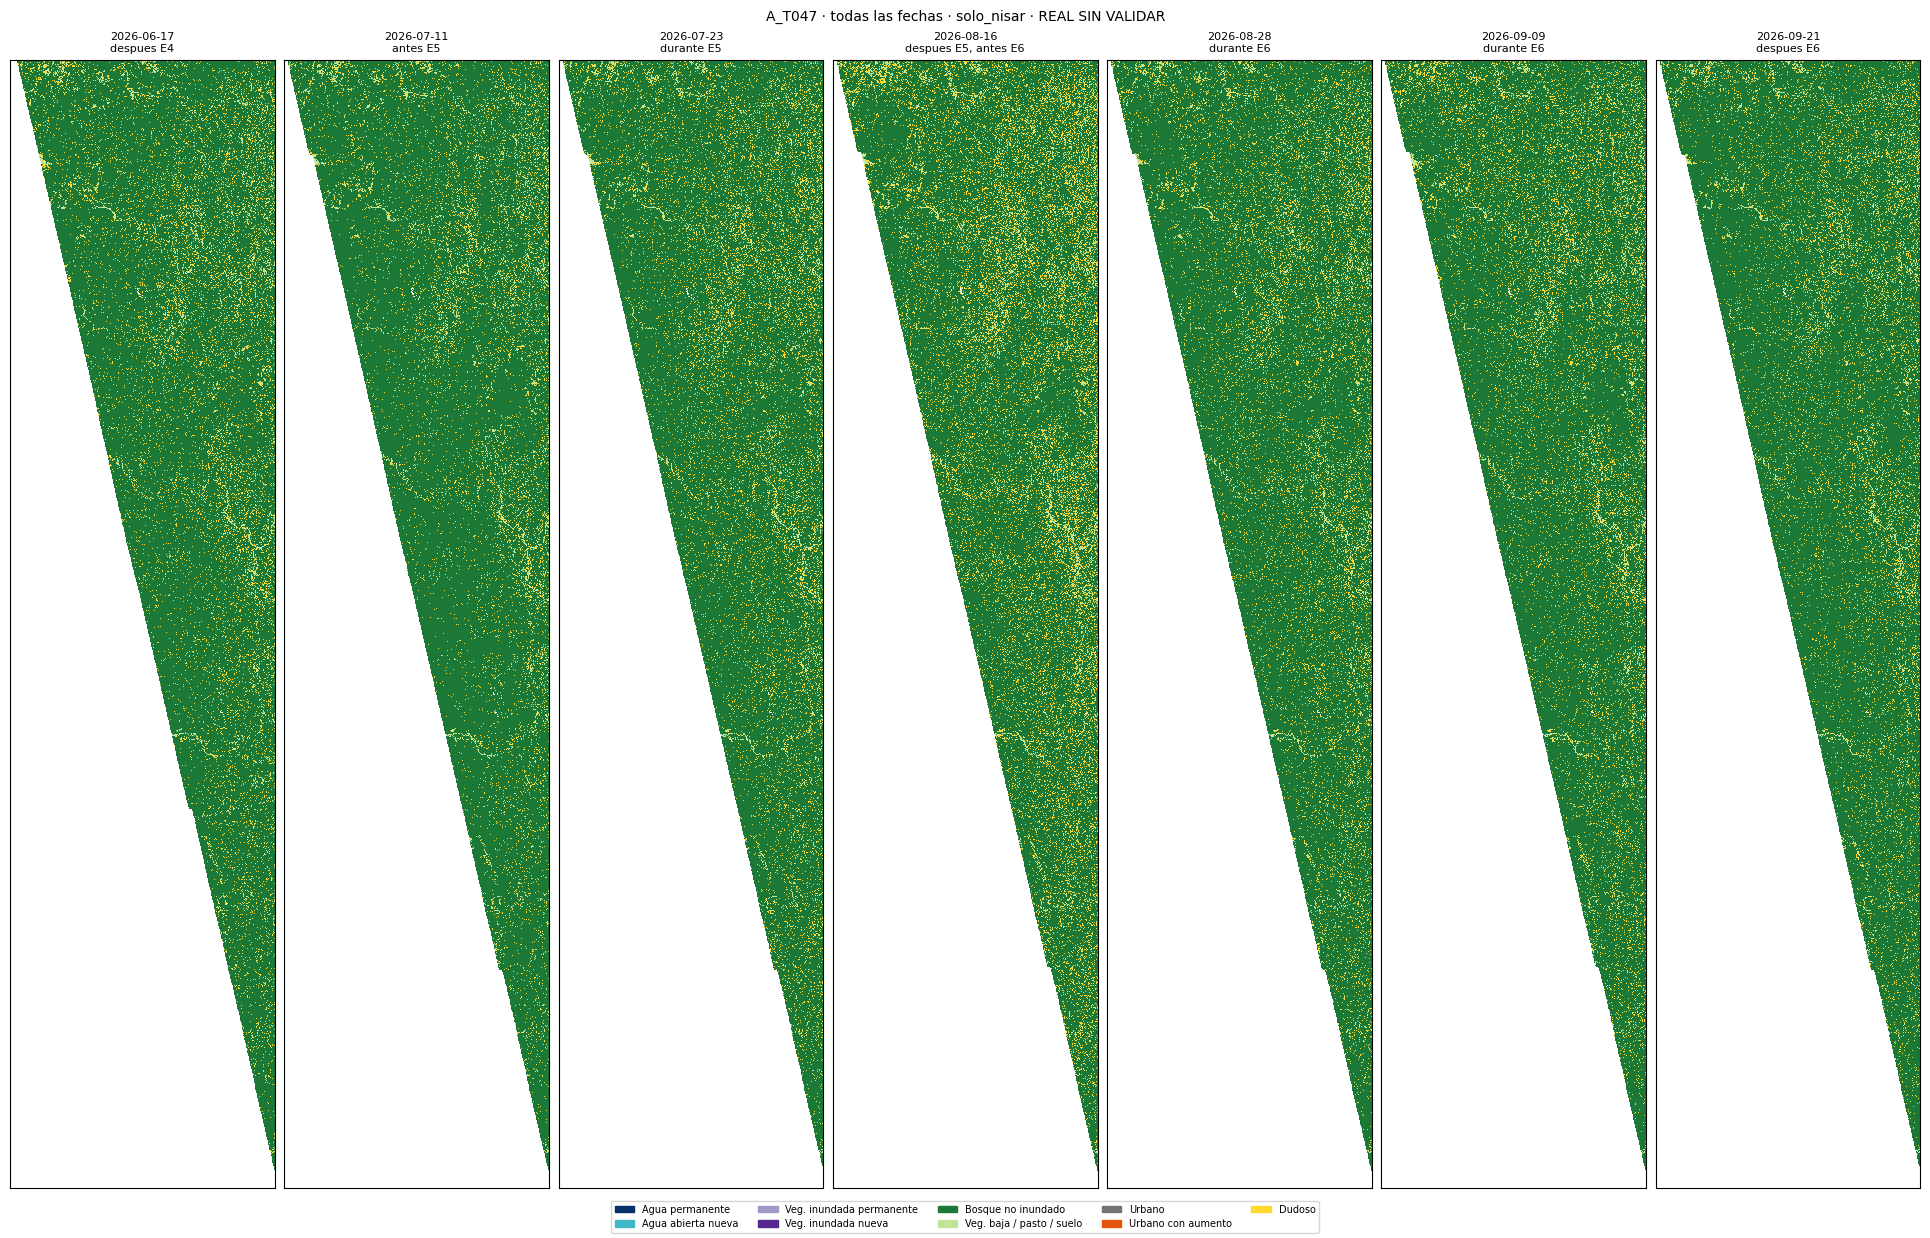

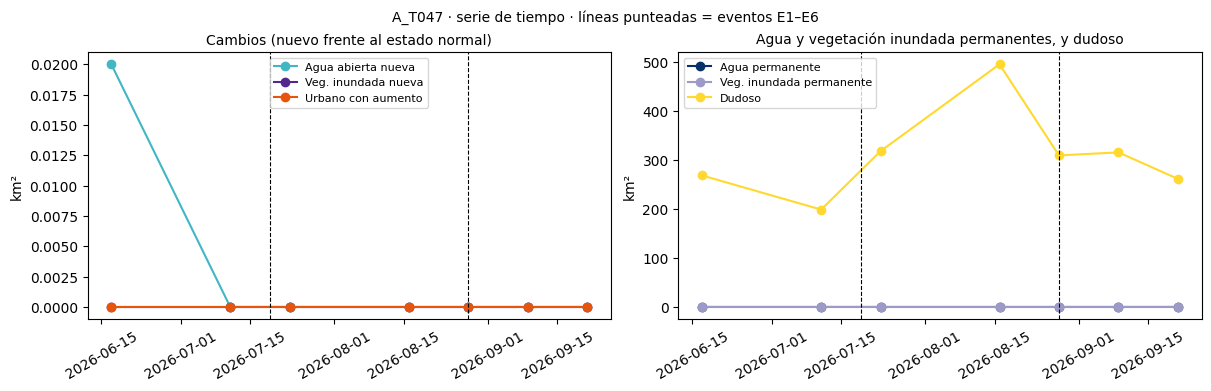

Tiempo                      : 552 s
 stack      fecha                          papel  cubre_km2  2_Agua abierta nueva_km2  4_Veg. inundada nueva_km2  7_Urbano_km2  9_Dudoso_km2
A_T148 2026-06-24                     despues E4   10834.11                      2.21                       2.60          4.11       1946.34
A_T148 2026-07-06                       antes E5    4184.45                      0.00                       0.01          3.80        664.68
A_T148 2026-08-11           despues E5, antes E6   10830.99                      0.30                       0.48          4.11        393.82
A_T148 2026-09-04                     durante E6   10827.53                      4.16                       6.63          4.03        589.21
A_T148 2026-09-16                     despues E6   10826.02                      1.69                       0.12          4.02        539.18
D_T011 2026-06-26                     despues E4    9170.77                      1.12                       0.18      

In [6]:
# ---- 5. Run all stacks ----
SERIES, RUTAS, MALLAS = {}, {}, {}
for st in STACKS:
    if fechas_stack(st).empty:
        continue
    SERIES[st], RUTAS[st], MALLAS[st] = procesar_stack(st)

TABLA_SERIE = pd.concat(SERIES.values(), ignore_index=True)
TABLA_SERIE.round(3).to_csv(DIR_ZONA / f"serie_todos_los_stacks_{VARIANTE}.csv", index=False)
print(SEP)
print(TABLA_SERIE[["stack", "fecha", "papel", "cubre_km2", "2_Agua abierta nueva_km2", "4_Veg. inundada nueva_km2",
                   "7_Urbano_km2", "9_Dudoso_km2"]].round(2).to_string(index=False))

## 6. Link into `sucesos/`

In [7]:
def enlazar(origen, destino):
    destino.parent.mkdir(parents=True, exist_ok=True)
    if destino.exists():
        destino.unlink()
    try:
        os.link(origen, destino)
    except OSError:
        shutil.copy2(origen, destino)


FASE_DIR = {"antes": "1_antes", "durante": "2_durante", "despues": "3_despues"}
n_enl = 0
for st, rutas in RUTAS.items():
    for f, rr in rutas.items():
        for p in papeles(st).get(f, []):
            fase, ev = p.split()
            carpetas = sorted(DIR_SUCESOS.glob(f"{ev}_*"))
            if not carpetas:
                continue
            destinos = [carpetas[0] / "por_region" / st / FASE_DIR[fase] / f]
            destinos += sorted((carpetas[0] / "cronologico").glob(f"{f}_*_{st}_{fase}_*"))
            for d in destinos:
                for clave in ("clases", "png", "LR", "pmax"):
                    if clave in rr:
                        enlazar(rr[clave], d / rr[clave].name)
                        n_enl += 1
                enlazar(rr["clases"].with_suffix(".json"), d / rr["clases"].with_suffix(".json").name)
print(SEP)
renglon("Enlaces en sucesos/", n_enl)

Enlaces en sucesos/         : 120
